In [1]:
!pip install -q datasets

import re
from datasets import load_dataset
from collections import Counter
import matplotlib.pyplot as plt

print("дамп української Вікіпедії")

wiki_dataset = load_dataset("wikimedia/wikipedia", "20231101.uk", split="train", streaming=True)

sentences = []
target_sentences_count = 300000

ukrainian_letters_pattern = re.compile(r"[^a-щьюяєіїґ' \-]|\b\-\b")

print("Обробка та очищення текстів...")

for article in wiki_dataset:
    text = article["text"]
    if not text:
        continue

    text = text.lower()

    raw_sentences = re.split(r'[\.\!\?]+', text)

    for raw_sent in raw_sentences:

        cleaned_text = re.sub(r'[^а-щьюяєіїґ\'\s\-]', ' ', raw_sent)

        cleaned_text = re.sub(r'\s+', ' ', cleaned_text).strip()

        words = cleaned_text.split()

        filtered_words = []
        for w in words:
            w = w.strip('-')

            if len(w) >= 3:
                filtered_words.append(w)

        if len(filtered_words) >= 5:
            sentences.append(filtered_words)

            if len(sentences) >= target_sentences_count:
                break

    if len(sentences) >= target_sentences_count:
        break

print(f"\nЗібрано та успішно оброблено речень: {len(sentences)}")
print("\nПриклади перших 5 очищених речень:")
for i, s in enumerate(sentences[:5], 1):
    print(f"{i}. {s}")

дамп української Вікіпедії


README.md:   0%|          | 0.00/131k [00:00<?, ?B/s]

Обробка та очищення текстів...

Зібрано та успішно оброблено речень: 300000

Приклади перших 5 очищених речень:
1. ['земле', 'пис', 'від', 'опис', 'землі', 'земля', 'писати', 'описувати', 'система', 'наук', 'вивчає', 'географічну', 'оболонку', 'землі', 'епігеосферу', 'просторову', 'природну', 'соціально-економічну', 'різноманітність', 'господарство', 'населення', 'планети', 'окремих', 'регіонів', 'країн', 'також', "зв'язки", 'між', 'природним', 'середовищем', 'діяльністю', 'людини']
2. ['сучасному', 'розумінні', 'поняття', 'географія', 'заміщено', 'поняттям', 'географічні', 'науки']
3. ['поняття', 'уперше', 'термін', 'географія', 'був', 'запропонований', 'давньогрецьким', 'географом', 'ератосфеном']
4. ['структура', 'основне', 'завдання', 'сучасної', 'географії', 'полягає', 'вивченні', 'законів', 'закономірностей', 'розміщення', 'взаємодії', 'компонентів', 'географічного', 'середовища', 'їхніх', 'поєднань', 'різних', 'рівнях']
5. ['складність', "об'єкта", 'дослідження', 'широта', 'пред

Загальна кількість речень: 300000
Кількість унікальних слів: 306876

Топ-20 найчастіших слів:
  року: 27475
  від: 17309
  також: 13375
  для: 13324
  його: 13166
  україни: 12610
  про: 12083
  під: 10012
  році: 9537
  було: 9205
  був: 7918
  району: 7875
  після: 7597
  він: 7549
  які: 7253
  або: 6852
  населення: 6715
  території: 6548
  час: 6252
  області: 6171


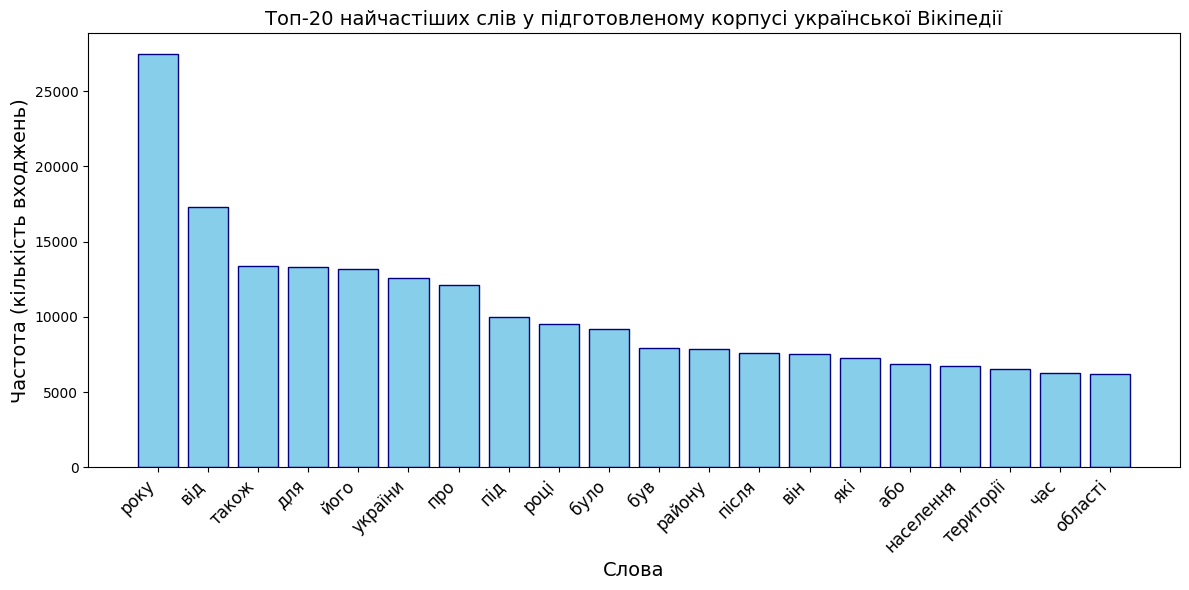

In [2]:
from collections import Counter
import matplotlib.pyplot as plt

all_words = [word for sentence in sentences for word in sentence]

total_sentences = len(sentences)
unique_words = set(all_words)
total_unique_words = len(unique_words)

word_counts = Counter(all_words)
top_20_words = word_counts.most_common(20)

print(f"Загальна кількість речень: {total_sentences}")
print(f"Кількість унікальних слів: {total_unique_words}")
print("\nТоп-20 найчастіших слів:")
for word, freq in top_20_words:
    print(f"  {word}: {freq}")

words, frequencies = zip(*top_20_words)

plt.figure(figsize=(12, 6))
plt.bar(words, frequencies, color='skyblue', edgecolor='navy')
plt.xticks(rotation=45, ha='right', fontsize=12)
plt.xlabel('Слова', fontsize=14)
plt.ylabel('Частота (кількість входжень)', fontsize=14)
plt.title('Топ-20 найчастіших слів у підготовленому корпусі української Вікіпедії', fontsize=14)
plt.tight_layout()
plt.show()